In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD, PCA

In [ ]:
wine_data = load_wine()

df = pd.DataFrame(data=wine_data.data, columns=wine_data.feature_names)
target = wine_data.target

print(f"Розмір матриці ознак (рядки, стовпці): {df.shape}")

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

Розмір матриці ознак (рядки, стовпці): (178, 13)


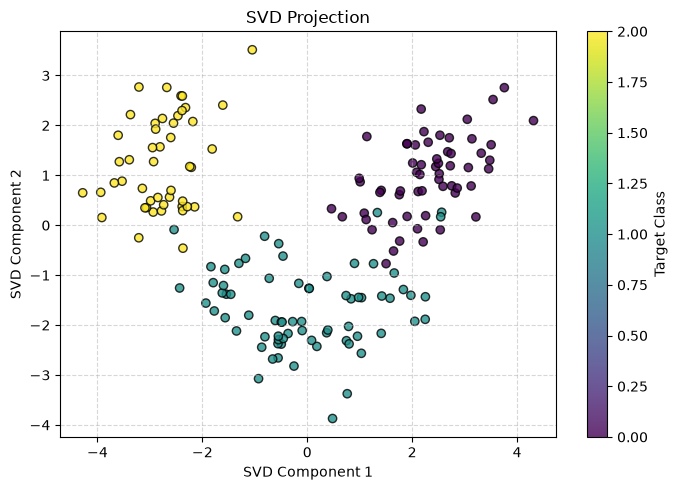

In [ ]:
svd = TruncatedSVD(n_components=2, random_state=42)
svd_transformed = svd.fit_transform(scaled_data)

plt.figure(figsize=(7, 5))
scatter_svd = plt.scatter(
    svd_transformed[:, 0], 
    svd_transformed[:, 1], 
    c=target, 
    cmap='viridis', 
    edgecolors='k', 
    alpha=0.8
)
plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("SVD Projection")
plt.colorbar(scatter_svd, label='Target Class')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

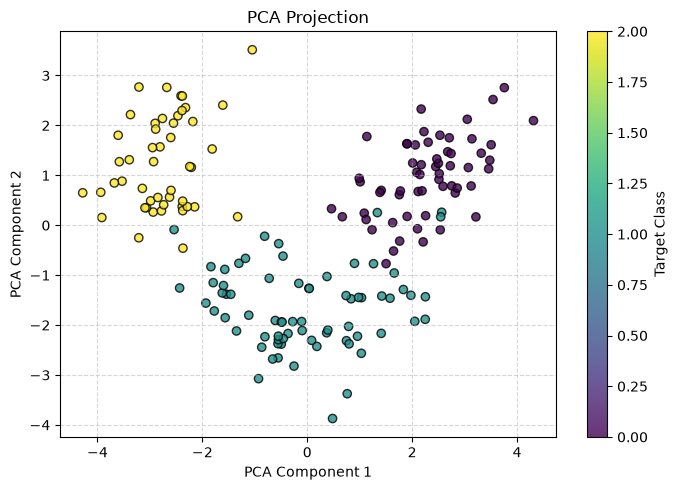

In [ ]:
pca = PCA(n_components=2, random_state=42)
pca_transformed = pca.fit_transform(scaled_data)

plt.figure(figsize=(7, 5))
scatter_pca = plt.scatter(
    pca_transformed[:, 0], 
    pca_transformed[:, 1], 
    c=target, 
    cmap='viridis', 
    edgecolors='k', 
    alpha=0.8
)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("PCA Projection")
plt.colorbar(scatter_pca, label='Target Class')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Частка поясненої дисперсії PCA:
  - Головна компонента 1: 0.3620 (36.20%)
  - Головна компонента 2: 0.1921 (19.21%)
  - Сумарно: 0.5541 (55.41%)


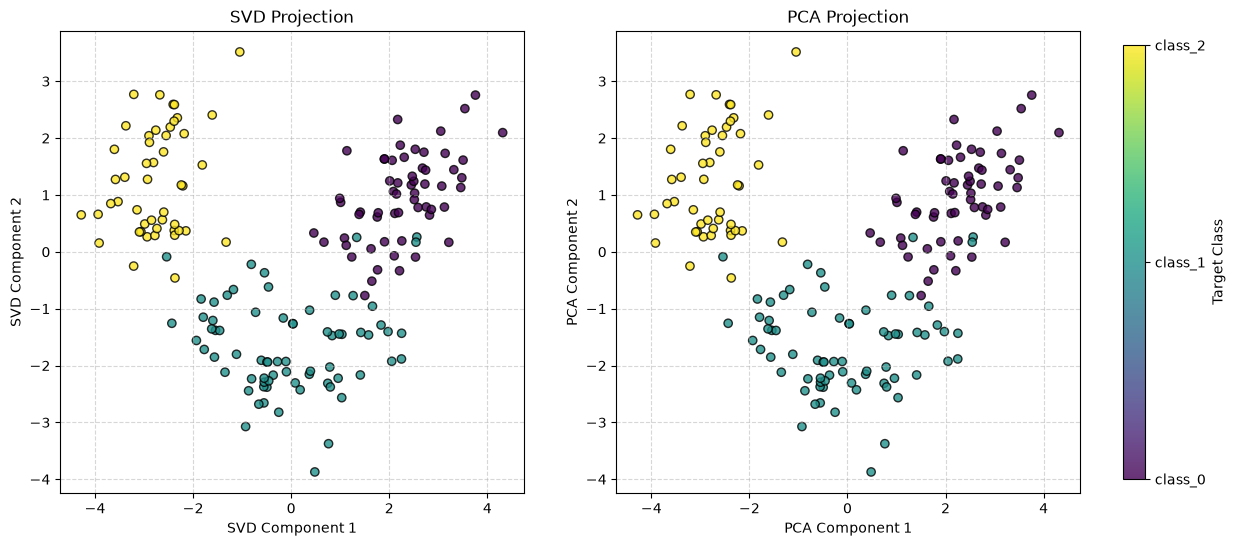

Графік успішно збережено у файл: dimensionality_reduction_comparison.png


In [ ]:
explained_variance = pca.explained_variance_ratio_
print(f"Частка поясненої дисперсії PCA:")
print(f"  - Головна компонента 1: {explained_variance[0]:.4f} ({explained_variance[0]*100:.2f}%)")
print(f"  - Головна компонента 2: {explained_variance[1]:.4f} ({explained_variance[1]*100:.2f}%)")
print(f"  - Сумарно: {explained_variance.sum():.4f} ({explained_variance.sum()*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

scatter1 = axes[0].scatter(
    svd_transformed[:, 0], 
    svd_transformed[:, 1], 
    c=target, 
    cmap='viridis', 
    edgecolors='k', 
    alpha=0.8
)
axes[0].set_xlabel("SVD Component 1")
axes[0].set_ylabel("SVD Component 2")
axes[0].set_title("SVD Projection")
axes[0].grid(True, linestyle='--', alpha=0.5)

scatter2 = axes[1].scatter(
    pca_transformed[:, 0], 
    pca_transformed[:, 1], 
    c=target, 
    cmap='viridis', 
    edgecolors='k', 
    alpha=0.8
)
axes[1].set_xlabel("PCA Component 1")
axes[1].set_ylabel("PCA Component 2")
axes[1].set_title("PCA Projection")
axes[1].grid(True, linestyle='--', alpha=0.5)

cbar = fig.colorbar(scatter2, ax=axes, orientation='vertical', fraction=0.02, pad=0.04)
cbar.set_label('Target Class')
cbar.set_ticks(range(len(wine_data.target_names)))
cbar.set_ticklabels(wine_data.target_names)

output_filename = "dimensionality_reduction_comparison.png"
plt.savefig(output_filename, dpi=300, bbox_inches='tight')
plt.show()

print(f"Графік успішно збережено у файл: {output_filename}")